In [1]:
import pandas as pd
import numpy as np
import json
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

BASE = Path(r"C:\Users\Administrator\credit-scoring-lc")
PROC = BASE / "data" / "processed"
train_d = pd.read_parquet(PROC / "train_features.parquet")
test_d  = pd.read_parquet(PROC / "test_features.parquet")

drop_cols = ["id", "issue_date", "issue_year", "split", "default_flag", "addr_state"]
feature_cols = [c for c in train_d.columns if c not in drop_cols]
y_train, y_test = train_d["default_flag"], test_d["default_flag"]

# 逻辑回归 v2
rules = json.loads((BASE / "reports" / "preprocessing_rules.json").read_text(encoding="utf-8"))
cols_v2 = rules["logistic_v2_features"]
sc2 = StandardScaler().fit(train_d[cols_v2])
lr2 = LogisticRegression(max_iter=1000).fit(sc2.transform(train_d[cols_v2]), y_train)
lr_train = lr2.predict_proba(sc2.transform(train_d[cols_v2]))[:, 1]
lr_test  = lr2.predict_proba(sc2.transform(test_d[cols_v2]))[:, 1]

# XGBoost
xgb = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                    subsample=0.8, colsample_bytree=0.8, min_child_weight=50,
                    eval_metric="auc", random_state=42, n_jobs=-1)
xgb.fit(train_d[feature_cols], y_train)
xgb_train = xgb.predict_proba(train_d[feature_cols])[:, 1]
xgb_test  = xgb.predict_proba(test_d[feature_cols])[:, 1]

print("逻辑回归v2 test AUC:", round(roc_auc_score(y_test, lr_test), 4))
print("XGBoost    test AUC:", round(roc_auc_score(y_test, xgb_test), 4))

逻辑回归v2 test AUC: 0.6586
XGBoost    test AUC: 0.6721


In [2]:
def psi(expected, actual, bins=10):
    cuts = np.quantile(expected, np.linspace(0, 1, bins + 1))
    cuts[0], cuts[-1] = -np.inf, np.inf          # 两端放开，测试集超出范围的人也能归档
    cuts = np.unique(cuts)
    e = np.histogram(expected, cuts)[0] / len(expected)
    a = np.histogram(actual,   cuts)[0] / len(actual)
    e, a = np.clip(e, 1e-6, None), np.clip(a, 1e-6, None)   # 避免占比为0时算不出对数
    return float(np.sum((a - e) * np.log(a / e))), e, a

psi_lr,  e_lr,  a_lr  = psi(lr_train,  lr_test)
psi_xgb, e_xgb, a_xgb = psi(xgb_train, xgb_test)

print("逻辑回归v2 分数 PSI:", round(psi_lr, 4))
print("XGBoost    分数 PSI:", round(psi_xgb, 4))

pd.DataFrame({"train占比": e_xgb, "test占比": a_xgb}).round(3).assign(档=range(1, len(e_xgb) + 1)).set_index("档")

逻辑回归v2 分数 PSI: 0.0027
XGBoost    分数 PSI: 0.0019


,train占比,test占比
档,,
1,0.1,0.105
2,0.1,0.096
3,0.1,0.096
4,0.1,0.098
5,0.1,0.096
6,0.1,0.098
7,0.1,0.098
8,0.1,0.100
9,0.1,0.102


In [3]:
def psi_feat(col):
    tr, te = train_d[col], test_d[col]
    if tr.nunique() <= 12:                      # 取值很少的变量：按每个取值直接比占比
        vals = sorted(set(tr.unique()) | set(te.unique()))
        e = tr.value_counts(normalize=True).reindex(vals, fill_value=0).values
        a = te.value_counts(normalize=True).reindex(vals, fill_value=0).values
        e, a = np.clip(e, 1e-6, None), np.clip(a, 1e-6, None)
        return float(np.sum((a - e) * np.log(a / e)))
    return psi(tr.values, te.values)[0]         # 取值多的变量：分10档

psi_table = pd.Series({c: psi_feat(c) for c in feature_cols}).sort_values(ascending=False)
print(psi_table.round(4).head(10))

print("\n平均预测违约概率 vs 实际违约率")
print("逻辑回归v2  训练:", round(lr_train.mean(), 4),  " 测试:", round(lr_test.mean(), 4))
print("XGBoost     训练:", round(xgb_train.mean(), 4), " 测试:", round(xgb_test.mean(), 4))
print("实际违约率  训练:", round(y_train.mean(), 4),   " 测试:", round(y_test.mean(), 4))

initial_list_status_w                  0.1424
verification_status_Source Verified    0.0539
inq_last_6mths                         0.0408
dti                                    0.0239
revol_util                             0.0212
mths_since_last_record                 0.0154
open_acc                               0.0091
pub_rec                                0.0067
credit_hist_months                     0.0065
revol_bal                              0.0063
dtype: float64

平均预测违约概率 vs 实际违约率
逻辑回归v2  训练: 0.1319  测试: 0.1321
XGBoost     训练: 0.1319  测试: 0.1338
实际违约率  训练: 0.1319  测试: 0.1489


In [4]:
def cutoff_table(y_te, p_te, p_tr, rates=(0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3)):
    y_te, p_te = np.asarray(y_te), np.asarray(p_te)
    total_bad = y_te.sum()
    rows = []
    for r in rates:
        cut = np.quantile(p_tr, r)           # 分数线只来自训练集
        ok = p_te <= cut                      # 分数低于线 = 通过
        rows.append({"训练集通过率": r,
                     "分数线": cut,
                     "测试集通过率": ok.mean(),
                     "通过者坏账率": y_te[ok].mean(),
                     "被拒者坏账率": y_te[~ok].mean(),
                     "拦住坏客户比例": y_te[~ok].sum() / total_bad})
    return pd.DataFrame(rows).round(4)

print("2015年整体坏账率（不设分数线）:", round(y_test.mean(), 4))
cutoff_table(y_test, xgb_test, xgb_train)

2015年整体坏账率（不设分数线）: 0.1489


,训练集通过率,分数线,测试集通过率,通过者坏账率,被拒者坏账率,拦住坏客户比例
0,0.9,0.2227,0.8894,0.1310,0.2927,0.2174
1,0.8,0.1854,0.7879,0.1180,0.2634,0.3754
2,0.7,0.1600,0.6882,0.1069,0.2414,0.5056
3,0.6,0.1398,0.5900,0.0961,0.2248,0.6192
4,0.5,0.1219,0.4917,0.0857,0.2099,0.7168
5,0.4,0.1058,0.3952,0.0747,0.1973,0.8016
6,0.3,0.0901,0.2972,0.0641,0.1847,0.8720


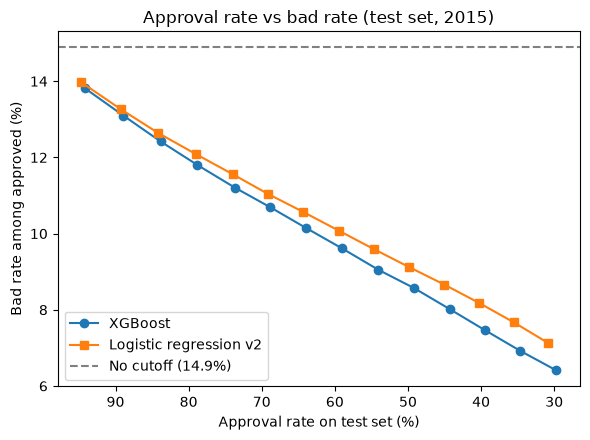

,通过率(XGB),坏账率(XGB),通过率(LR),坏账率(LR)
0,0.9422,0.1382,0.9467,0.1397
1,0.8894,0.1310,0.8931,0.1327
2,0.8384,0.1242,0.8415,0.1264
3,0.7879,0.1180,0.7903,0.1209
4,0.7370,0.1121,0.7398,0.1156
5,0.6882,0.1069,0.6913,0.1104
6,0.6396,0.1015,0.6434,0.1057
7,0.5900,0.0961,0.5949,0.1008
8,0.5405,0.0905,0.5464,0.0959
9,0.4917,0.0857,0.4983,0.0912


In [5]:
import matplotlib.pyplot as plt

rates = [0.95, 0.9, 0.85, 0.8, 0.75, 0.7, 0.65, 0.6, 0.55, 0.5, 0.45, 0.4, 0.35, 0.3]
tab_x = cutoff_table(y_test, xgb_test, xgb_train, rates=rates)
tab_l = cutoff_table(y_test, lr_test,  lr_train,  rates=rates)

tab_x.to_csv(BASE / "reports" / "cutoff_xgboost.csv", index=False, encoding="utf-8-sig")
tab_l.to_csv(BASE / "reports" / "cutoff_logistic_v2.csv", index=False, encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(tab_x["测试集通过率"] * 100, tab_x["通过者坏账率"] * 100, marker="o", label="XGBoost")
ax.plot(tab_l["测试集通过率"] * 100, tab_l["通过者坏账率"] * 100, marker="s", label="Logistic regression v2")
ax.axhline(y_test.mean() * 100, linestyle="--", color="gray",
           label=f"No cutoff ({y_test.mean()*100:.1f}%)")
ax.set_xlabel("Approval rate on test set (%)")
ax.set_ylabel("Bad rate among approved (%)")
ax.set_title("Approval rate vs bad rate (test set, 2015)")
ax.invert_xaxis()
ax.legend()
plt.tight_layout()
fig.savefig(BASE / "reports" / "figures" / "approval_vs_badrate.png", dpi=150)
plt.show()

pd.DataFrame({"通过率(XGB)": tab_x["测试集通过率"], "坏账率(XGB)": tab_x["通过者坏账率"],
              "通过率(LR)": tab_l["测试集通过率"],  "坏账率(LR)": tab_l["通过者坏账率"]})